# Phase 2: Tumour segmentation (evangeline, patient 29)

Sauvola, a distance-transform watershed and Chan-Vese inside the liver, scored with the ground-truth liver, the predicted liver and its convex hull.

## Step 0: Setup

Imports, folders and charvi's liver pipeline.

In [1]:
import os
import glob
import sys
import numpy as np
import cv2
import matplotlib.pyplot as plt
import pandas as pd
from scipy import ndimage as ndi
from skimage.filters import threshold_sauvola, sobel
from skimage.morphology import h_maxima
from skimage.segmentation import watershed, morphological_chan_vese
from skimage.measure import label, regionprops

sys.path.insert(0, "../app")
import pipeline_charvi                     # the group's liver segmentation, used for the "predicted liver" scores

NAME = "evangeline"
ENH = "../phase1/outputs_evangeline/enhanced"     # Phase 1 output
GT = "../data/slices/" + NAME                     # ground-truth masks
OUT = "outputs_evangeline"
FIGS = "../report/figures/evangeline"
FAILED = "../report/failed_cases/evangeline"
METHODS = ["sauvola", "watershed", "chanvese"]
for m in METHODS:
    os.makedirs(OUT + "/" + m, exist_ok=True)
os.makedirs(OUT + "/predicted_liver", exist_ok=True)
os.makedirs(FIGS, exist_ok=True)
os.makedirs(FAILED, exist_ok=True)

# list all the enhanced slices from Phase 1
files = sorted(glob.glob(ENH + "/*_enh.png"))
print(len(files), "enhanced slices found")

22 enhanced slices found


In [2]:
def load(p):
    # enhanced image (0-255) + ground-truth liver mask + ground-truth tumour mask
    slice_id = os.path.basename(p).replace("_enh.png", "")
    enhanced_img = cv2.imread(p, 0)
    liver_mask = cv2.imread(GT + "/" + slice_id + "_liver.png", 0) > 0
    gt_mask = cv2.imread(GT + "/" + slice_id + "_tumour.png", 0) > 0
    return slice_id, enhanced_img, liver_mask, gt_mask


def dice(pred_mask, gt_mask):
    # Dice = 2|A n B| / (|A| + |B|). 1 = perfect overlap, 0 = none
    overlap = (pred_mask & gt_mask).sum()
    return 2 * overlap / (pred_mask.sum() + gt_mask.sum() + 1e-9)


def iou(pred_mask, gt_mask):
    # Jaccard / IoU = |A n B| / |A u B|
    overlap = (pred_mask & gt_mask).sum()
    union = (pred_mask | gt_mask).sum()
    return overlap / (union + 1e-9)


def overlay(img, pred_mask, gt_mask):
    # RED = predicted outline, GREEN = ground-truth outline
    rgb = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)
    contours, _ = cv2.findContours(gt_mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    cv2.drawContours(rgb, contours, -1, (0, 255, 0), 2)
    contours, _ = cv2.findContours(pred_mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    cv2.drawContours(rgb, contours, -1, (255, 0, 0), 2)
    return rgb

## Step 1: The example slice

The slice with the biggest tumour, zoomed on the liver.

example slice: p29_s69


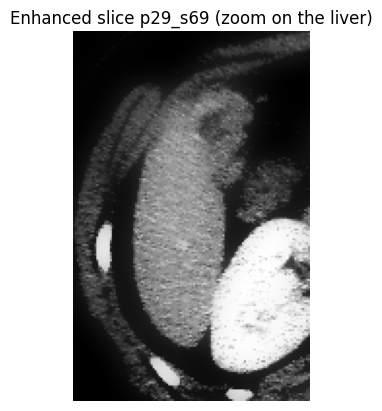

In [3]:
# example slice for the figures: the one with the biggest tumour
example = files[0]
biggest = -1
for f in files:
    slice_id, enhanced_img, liver_mask, gt_mask = load(f)
    if gt_mask.sum() > biggest:
        biggest = gt_mask.sum()
        example = f

sid, img, liver, gt = load(example)

# zoom window on the liver (30 pixel border), used in the figures
ys, xs = np.where(liver)
r0 = max(ys.min() - 30, 0)
r1 = ys.max() + 30
c0 = max(xs.min() - 30, 0)
c1 = xs.max() + 30
print("example slice:", sid)

# read the image -> show it
plt.figure()
plt.imshow(img[r0:r1, c0:c1], cmap='gray')
plt.title('Enhanced slice ' + sid + ' (zoom on the liver)')
plt.axis('off')
plt.show()

## Step 2: Hexagon structuring element and a first threshold

My hexagon element, a rough threshold at the liver median - 20 and the four basic operations.

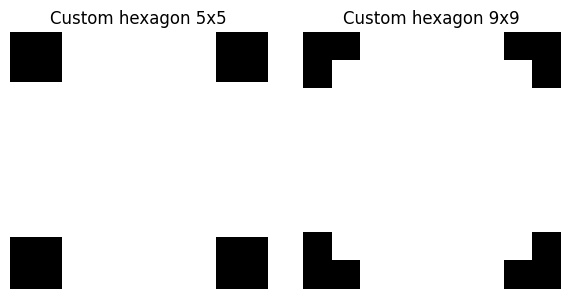

In [4]:
# ---- structuring elements ----
def hexagon(n):
    # hand-made hexagon: rounder than a square, straight sides unlike a disc
    se = np.zeros((n, n), np.uint8)
    c = n // 2
    q = (n + 1) // 4
    for r in range(n):
        cut = max(0, abs(r - c) - (c - q))           # how many pixels to cut off on each side of this row
        se[r, cut:n - cut] = 1
    return se

SE_HEX_5 = hexagon(5)          # 5 for opening (remove specks)
SE_HEX_9 = hexagon(9)          # 9 for closing (join pieces)

se_list = [SE_HEX_5, SE_HEX_9]
se_titles = ["Custom hexagon 5x5", "Custom hexagon 9x9"]
fig, ax = plt.subplots(1, 2, figsize=(6, 3))
for i in range(2):
    ax[i].imshow(se_list[i], cmap="gray")
    ax[i].set_title(se_titles[i])
    ax[i].axis("off")
plt.tight_layout()
plt.show()

In [5]:
def liver_roi(liver):
    # erode the liver a little (5x5 square) so its dark border is not mistaken for tumour
    square_5 = cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5))
    return cv2.erode(liver.astype(np.uint8), square_5) > 0


def clean(mask, min_area=30):
    # opening (hexagon 5) removes specks, small blobs are dropped (connected components)
    # closing (hexagon 9) + hole filling smooth the result
    mask = cv2.morphologyEx(mask.astype(np.uint8), cv2.MORPH_OPEN, SE_HEX_5) > 0
    lab = label(mask)
    keep = []
    for r in regionprops(lab):
        if r.area >= min_area:
            keep.append(r.label)
    mask = np.isin(lab, keep)
    mask = cv2.morphologyEx(mask.astype(np.uint8), cv2.MORPH_CLOSE, SE_HEX_9) > 0
    return ndi.binary_fill_holes(mask)

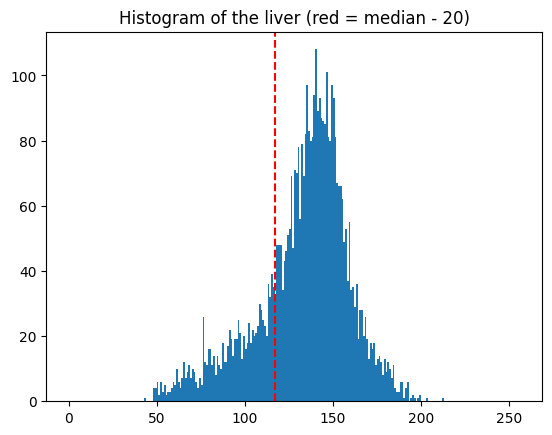

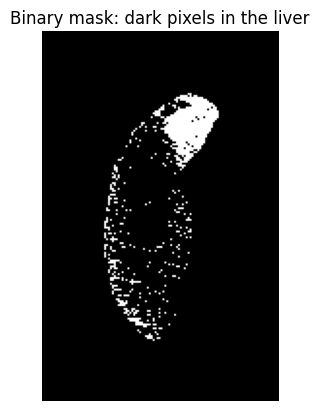

In [6]:
# look at the histogram of the liver to get a threshold (tumour = the dark side)
roi = liver_roi(liver)
rough_threshold = np.median(img[roi]) - 20

plt.figure()
plt.hist(img[roi].ravel(), bins=256, range=(0, 256))
plt.axvline(rough_threshold, color='red', linestyle='--')
plt.title('Histogram of the liver (red = median - 20)')
plt.show()

# makes a binary image: dark pixels inside the liver are 1 (white), the rest 0 (black)
rough = ((img < np.median(img[roi]) - 20) & roi).astype(np.uint8)
plt.figure()
plt.imshow(rough[r0:r1, c0:c1], cmap='gray')
plt.title('Binary mask: dark pixels in the liver')
plt.axis('off')
plt.show()

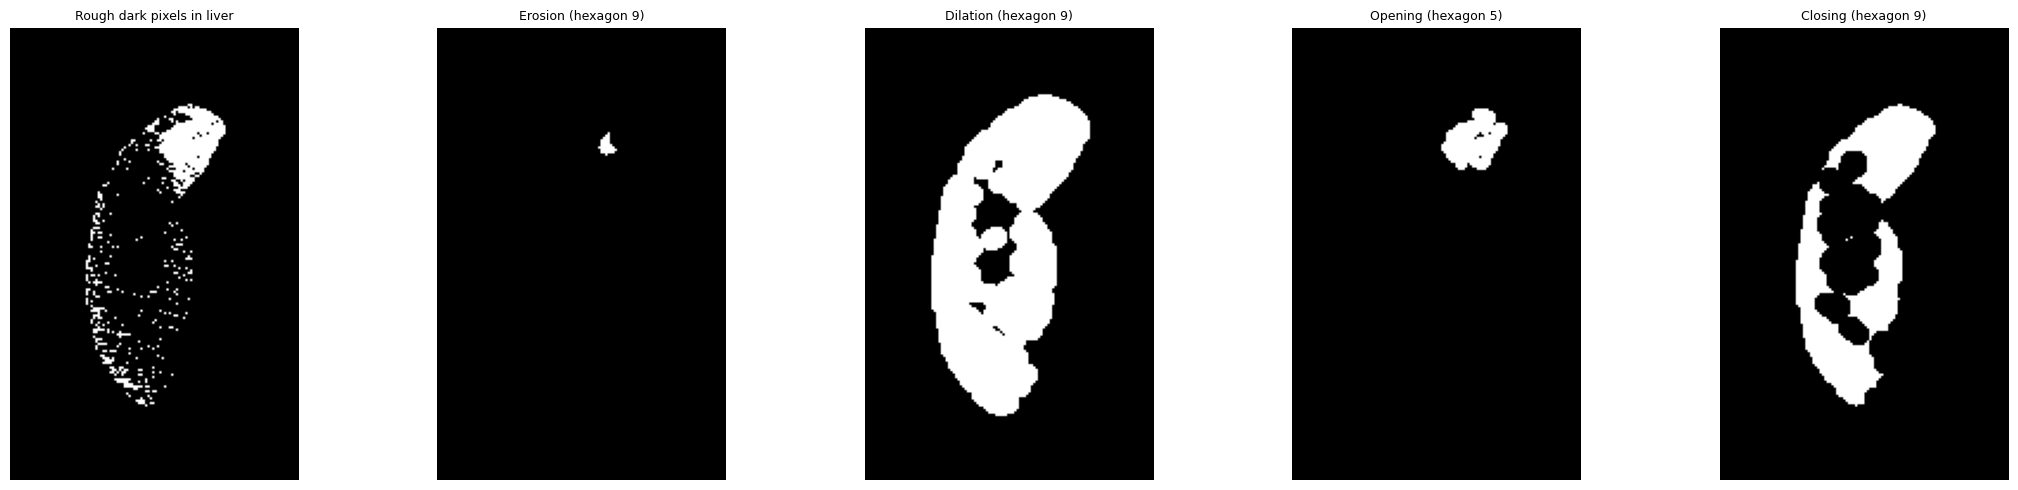

In [7]:
# erosion, dilation, opening and closing on the rough binary mask
eroded = cv2.erode(rough, SE_HEX_9)
dilated = cv2.dilate(rough, SE_HEX_9)
opened = cv2.morphologyEx(rough, cv2.MORPH_OPEN, SE_HEX_5)       # erode then dilate: removes specks
closed = cv2.morphologyEx(rough, cv2.MORPH_CLOSE, SE_HEX_9)      # dilate then erode: fills holes

# save the comparison figure for the report
morph_images = [rough, eroded, dilated, opened, closed]
morph_titles = ["Rough dark pixels in liver", "Erosion (hexagon 9)", "Dilation (hexagon 9)", "Opening (hexagon 5)", "Closing (hexagon 9)"]
fig, ax = plt.subplots(1, 5, figsize=(22, 5))
for i in range(5):
    ax[i].imshow(morph_images[i][r0:r1, c0:c1], cmap="gray")
    ax[i].set_title(morph_titles[i], fontsize=9)
    ax[i].axis("off")
plt.tight_layout()
plt.savefig(FIGS + "/" + NAME + "_p2_morphology.png", dpi=120)
plt.show()

## Step 3: Method A, Sauvola

T = m x (1 + k x (s / R - 1)) with a 101 x 101 window, k = 0.1, R = 128. It is less noisy than a plain local mean on uniform liver.

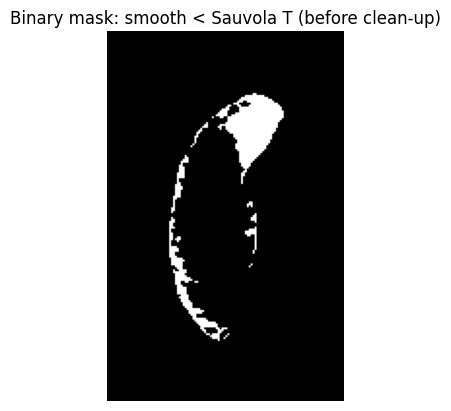

In [8]:
# ---- Method A: Sauvola local threshold ----
SAUVOLA_WINDOW = 101
SAUVOLA_K = 0.1
SAUVOLA_R = 128


def segment_sauvola(img, liver):
    roi = liver_roi(liver)
    if roi.sum() < 50:
        return np.zeros(img.shape, bool)
    smooth = cv2.GaussianBlur(img, (5, 5), 0).astype(float)   # Gaussian smoothing
    # pixels outside the liver are set to the liver median
    filled = smooth.copy()
    filled[~roi] = np.median(smooth[roi])
    # T = m x (1 + k x (s / R - 1)), one threshold per pixel
    T = threshold_sauvola(filled, window_size=SAUVOLA_WINDOW, k=SAUVOLA_K, r=SAUVOLA_R)
    return clean((smooth < T) & roi)


smooth = cv2.GaussianBlur(img, (5, 5), 0).astype(float)
filled = smooth.copy()
filled[~liver_roi(liver)] = np.median(smooth[liver_roi(liver)])
T = threshold_sauvola(filled, window_size=SAUVOLA_WINDOW, k=SAUVOLA_K, r=SAUVOLA_R)

# makes a binary image: darker than the local threshold T, inside the liver
sauvola_binary = (smooth < T) & liver_roi(liver)
plt.figure()
plt.imshow(sauvola_binary[r0:r1, c0:c1], cmap='gray')
plt.title('Binary mask: smooth < Sauvola T (before clean-up)')
plt.axis('off')
plt.show()

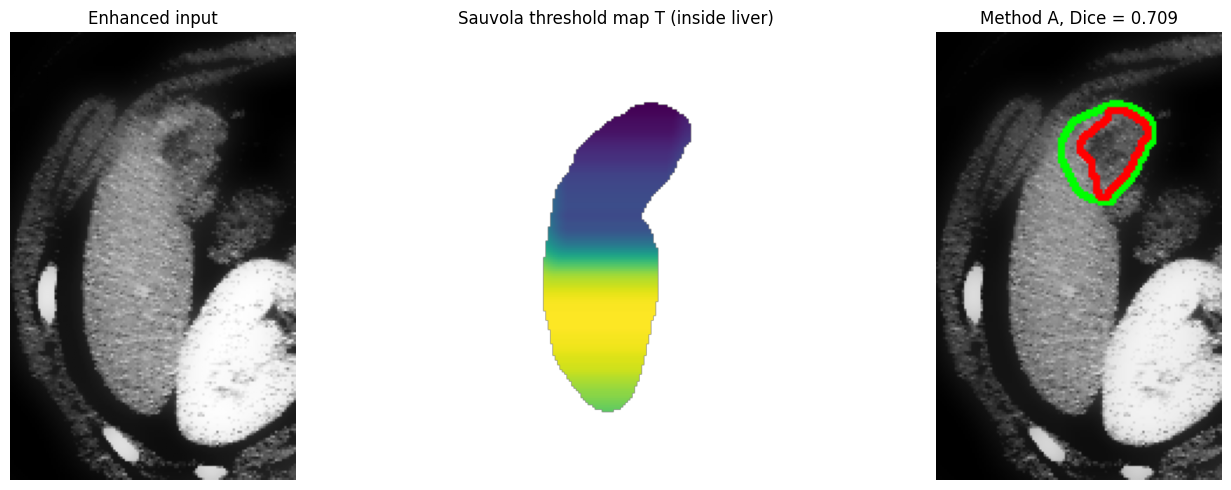

In [9]:
pred_a = segment_sauvola(img, liver)

# save the comparison figure for the report
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(img[r0:r1, c0:c1], cmap="gray")
ax[0].set_title("Enhanced input")
ax[1].imshow(np.where(liver, T, np.nan)[r0:r1, c0:c1], cmap="viridis")
ax[1].set_title("Sauvola threshold map T (inside liver)")
ax[2].imshow(overlay(img, pred_a, gt)[r0:r1, c0:c1])
ax[2].set_title(f"Method A, Dice = {dice(pred_a, gt):.3f}")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.savefig(FIGS + "/" + NAME + "_p2_method_a_sauvola.png", dpi=120)
plt.show()

## Step 4: Method B, watershed with distance-transform markers

h-maxima of the distance transform give one tumour marker per thick dark blob, then the watershed floods from all markers.

In [10]:
# ---- Method B: marker-controlled watershed ----
K = 0.75
H_PEAK = 2
GRAD_SIGMA = 3


def segment_watershed(img, liver, return_markers=False):
    roi = liver_roi(liver)
    markers = np.zeros(img.shape, np.int32)
    if roi.sum() < 50:
        if return_markers:
            return np.zeros(img.shape, bool), markers, np.zeros(img.shape)
        else:
            return np.zeros(img.shape, bool)
    smooth = cv2.GaussianBlur(img, (5, 5), 0)
    med = np.median(smooth[roi])
    sd = smooth[roi].std()

    # 1. dark candidate area: threshold + opening
    dark = ((smooth < med - K * sd) & roi).astype(np.uint8)
    candidates = cv2.morphologyEx(dark, cv2.MORPH_OPEN, SE_HEX_5)

    # 2. distance transform + h-maxima: one tumour marker per thick dark blob
    dist = cv2.distanceTransform(candidates, cv2.DIST_L2, 5)                  # distance to the candidate border
    peaks = h_maxima(dist, H_PEAK).astype(bool) & (candidates > 0)            # centres of thick dark blobs
    markers[peaks] = 2                                                        # tumour

    # 3. background markers: outside the (slightly dilated) liver + normal bright liver
    square_3 = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))
    dilated_liver = cv2.dilate(liver.astype(np.uint8), square_3).astype(bool)
    markers[~dilated_liver] = 1                                               # outside the liver
    markers[roi & (smooth > med) & (candidates == 0)] = 1                     # normal (bright) liver

    # 4. Gaussian smoothing + Sobel edges, then flood from the markers
    blurred = cv2.GaussianBlur(smooth, (0, 0), GRAD_SIGMA)
    gradient = sobel(blurred / 255.0)
    mask = clean((watershed(gradient, markers) == 2) & roi)
    if return_markers:
        return mask, markers, dist
    else:
        return mask

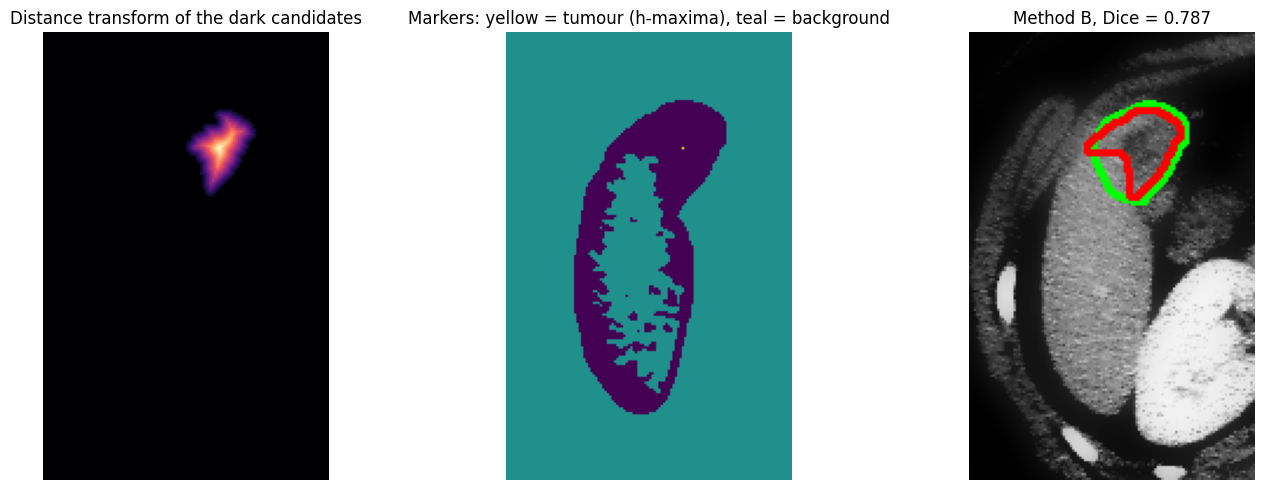

In [11]:
pred_b, markers, dist = segment_watershed(img, liver, return_markers=True)

# save the comparison figure for the report
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(dist[r0:r1, c0:c1], cmap="magma")
ax[0].set_title("Distance transform of the dark candidates")
ax[1].imshow(markers[r0:r1, c0:c1], cmap="viridis")
ax[1].set_title("Markers: yellow = tumour (h-maxima), teal = background")
ax[2].imshow(overlay(img, pred_b, gt)[r0:r1, c0:c1])
ax[2].set_title(f"Method B, Dice = {dice(pred_b, gt):.3f}")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.savefig(FIGS + "/" + NAME + "_p2_method_b_watershed.png", dpi=120)
plt.show()

## Step 5: Method C, Chan-Vese

It does not need edges, which suits my low-contrast tumour. 50 iterations, the darker region is the tumour.

In [12]:
# ---- Method C: Chan-Vese active contour ----
CV_ITERATIONS = 50
CV_START_K = 0.75


def segment_chanvese(img, liver, return_start=False):
    roi = liver_roi(liver)
    if roi.sum() < 50:
        if return_start:
            return np.zeros(img.shape, bool), roi
        else:
            return np.zeros(img.shape, bool)
    smooth = cv2.GaussianBlur(img, (5, 5), 0).astype(float) / 255

    # work on the liver's bounding box
    ys, xs = np.nonzero(roi)
    y0 = ys.min()
    y1 = ys.max() + 1
    x0 = xs.min()
    x1 = xs.max() + 1
    crop = smooth[y0:y1, x0:x1].copy()
    inside = roi[y0:y1, x0:x1]
    med = np.median(crop[inside])
    crop[~inside] = med                                                        # outside the liver = neutral grey

    # starting region = dark candidates
    start = (crop < med - CV_START_K * crop[inside].std()) & inside
    full_start = np.zeros(img.shape, bool)
    full_start[y0:y1, x0:x1] = start
    if not start.any():
        if return_start:
            return np.zeros(img.shape, bool), full_start
        else:
            return np.zeros(img.shape, bool)

    level_set = morphological_chan_vese(crop, num_iter=CV_ITERATIONS, init_level_set=start.astype(np.int8),
                                        smoothing=1, lambda1=1, lambda2=1).astype(bool)
    in_region = level_set & inside
    out_region = ~level_set & inside
    if in_region.any() and out_region.any() and crop[in_region].mean() > crop[out_region].mean():
        level_set = ~level_set                                                 # keep the DARKER region = tumour
    out = np.zeros(img.shape, bool)
    out[y0:y1, x0:x1] = level_set & inside
    out = clean(out)
    if return_start:
        return out, full_start
    else:
        return out

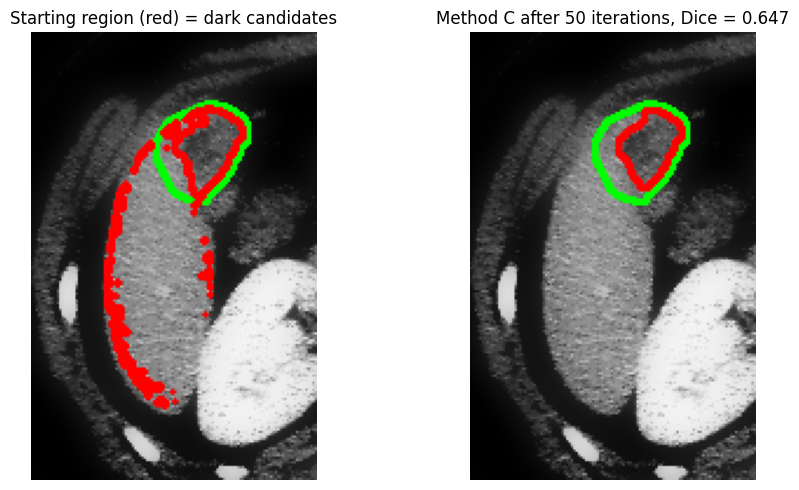

In [13]:
pred_c, start = segment_chanvese(img, liver, return_start=True)

# save the comparison figure for the report
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(overlay(img, start, gt)[r0:r1, c0:c1])
ax[0].set_title("Starting region (red) = dark candidates")
ax[1].imshow(overlay(img, pred_c, gt)[r0:r1, c0:c1])
ax[1].set_title(f"Method C after {CV_ITERATIONS} iterations, Dice = {dice(pred_c, gt):.3f}")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.savefig(FIGS + "/" + NAME + "_p2_method_c_chanvese.png", dpi=120)
plt.show()

## Step 6: Run all methods with all three search areas

Mean Dice and IoU per search area.

In [14]:
def run_method(method, img, liver):
    # call one of the three segmentation methods by name
    if method == "sauvola":
        return segment_sauvola(img, liver)
    elif method == "watershed":
        return segment_watershed(img, liver)
    else:
        return segment_chanvese(img, liver)


AREAS = ["predicted liver", "convex hull of predicted liver"]       # the two automatic (end-to-end) search areas
AREA_DIR = {}
AREA_DIR["predicted liver"] = "predicted_liver"
AREA_DIR["convex hull of predicted liver"] = "hull_liver"
for area in AREAS:
    os.makedirs(OUT + "/" + AREA_DIR[area], exist_ok=True)

metric_rows = []
metric_rows_pred = []
for f in files:
    slice_id, enhanced_img, liver_mask, gt_mask = load(f)
    ct = np.load(GT + "/" + slice_id + "_ct.npy")
    areas = {}
    for area in AREAS:                                         # predicted liver and its convex hull
        areas[area] = pipeline_charvi.search_area(ct, None, area)
    for method in METHODS:
        pred_mask = run_method(method, enhanced_img, liver_mask)   # search area = ground-truth liver (upper bound)
        cv2.imwrite(OUT + "/" + method + "/" + slice_id + "_tumour_pred.png", pred_mask.astype(np.uint8) * 255)
        row = {}
        row["slice"] = slice_id
        row["method"] = method
        row["Dice"] = dice(pred_mask, gt_mask)
        row["IoU"] = iou(pred_mask, gt_mask)
        row["GT tumour pixels"] = int(gt_mask.sum())
        metric_rows.append(row)
        for area in areas:                                     # end-to-end: no ground truth used to find the liver
            search_mask = areas[area]
            pred_mask = run_method(method, enhanced_img, search_mask)
            cv2.imwrite(OUT + "/" + AREA_DIR[area] + "/" + slice_id + "_" + method + "_tumour_pred.png", pred_mask.astype(np.uint8) * 255)
            row = {}
            row["slice"] = slice_id
            row["method"] = method
            row["search area"] = area
            row["Dice"] = dice(pred_mask, gt_mask)
            row["IoU"] = iou(pred_mask, gt_mask)
            row["GT tumour inside search area"] = (search_mask & gt_mask).sum() / max(gt_mask.sum(), 1)
            metric_rows_pred.append(row)

results = pd.DataFrame(metric_rows)
results.to_csv(OUT + "/phase2_metrics.csv", index=False)
results_pred = pd.DataFrame(metric_rows_pred)
results_pred.to_csv(OUT + "/phase2_metrics_predicted_liver.csv", index=False)

In [15]:
# mean Dice / IoU with each search area
summary = {}
summary["GT liver"] = results.groupby("method")[["Dice", "IoU"]].mean()
for area in AREAS:
    area_rows = results_pred[results_pred["search area"] == area]
    summary[area] = area_rows.groupby("method")[["Dice", "IoU"]].mean()
print(pd.concat(summary, axis=1).round(3))

print("\nPer slice Dice (GT liver):")
per_slice = results.pivot(index="slice", columns="method", values="Dice")
print(per_slice.round(3))

print("\nShare of the GT tumour inside each automatic search area, per slice:")
inside = results_pred.pivot_table(index="slice", columns="search area", values="GT tumour inside search area")
print(inside.round(2))

          GT liver        predicted liver         \
              Dice    IoU            Dice    IoU   
method                                             
chanvese     0.608  0.475           0.171  0.116   
sauvola      0.638  0.501           0.199  0.136   
watershed    0.458  0.356           0.174  0.126   

          convex hull of predicted liver         
                                    Dice    IoU  
method                                           
chanvese                           0.133  0.086  
sauvola                            0.178  0.119  
watershed                          0.144  0.105  

Per slice Dice (GT liver):
method   chanvese  sauvola  watershed
slice                                
p29_s56     0.000    0.000      0.000
p29_s57     0.382    0.368      0.553
p29_s58     0.505    0.505      0.465
p29_s59     0.677    0.672      0.714
p29_s60     0.746    0.749      0.749
p29_s61     0.729    0.768      0.758
p29_s62     0.774    0.754      0.112
p29_s63     0.799

## Step 7: Final method

Sauvola, because it had the best Dice with the ground-truth and the predicted liver.

method
chanvese     0.608
sauvola      0.638
watershed    0.458
final method: sauvola


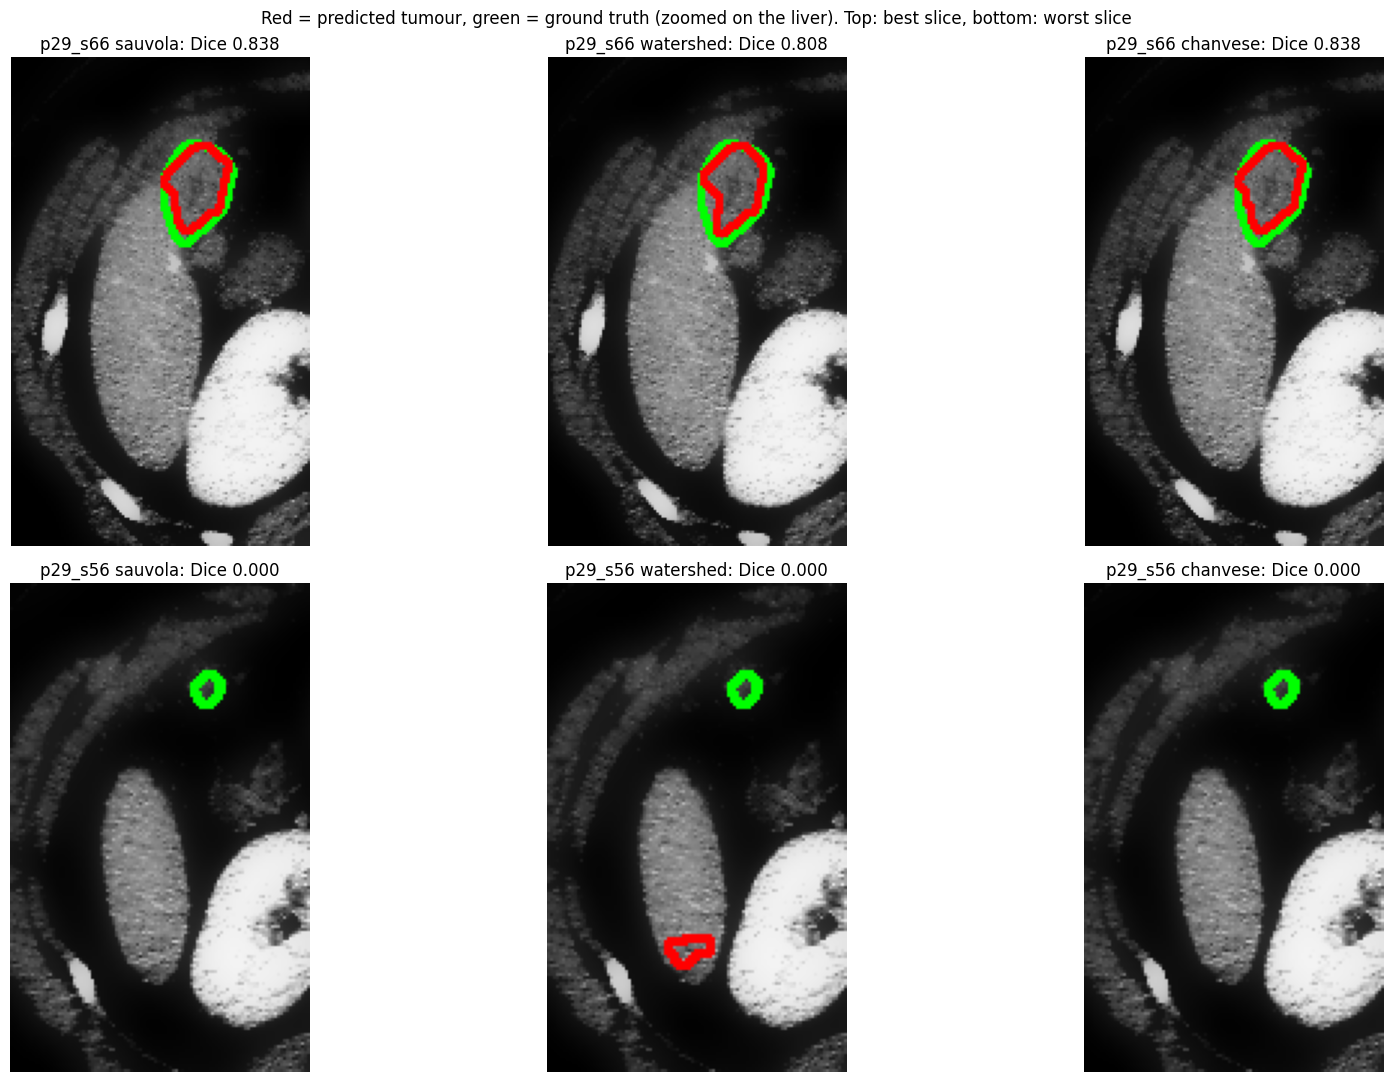

In [16]:
mean_dice = results.groupby("method")["Dice"].mean()
best_method = "sauvola"     # final = Sauvola (A): highest Dice with the GT liver and with the predicted liver
print(mean_dice.round(3).to_string())
print("final method:", best_method)

# best and worst slice of the final method
final_dice = results[results.method == best_method].set_index("slice")["Dice"]
best_sid = final_dice.idxmax()
worst_sid = final_dice.idxmin()

# save the comparison figure for the report (each row zoomed on that slice's liver)
panel_slices = [best_sid, worst_sid]
fig, ax = plt.subplots(2, 3, figsize=(18, 11))
for r in range(2):
    s = panel_slices[r]
    _, enhanced_img, liver_mask, gt_mask = load(ENH + "/" + s + "_enh.png")
    ys, xs = np.where(liver_mask)
    y0 = max(ys.min() - 30, 0)
    y1 = ys.max() + 30
    x0 = max(xs.min() - 30, 0)
    x1 = xs.max() + 30
    for c in range(3):
        method = METHODS[c]
        pred_mask = cv2.imread(OUT + "/" + method + "/" + s + "_tumour_pred.png", 0) > 0
        ax[r, c].imshow(overlay(enhanced_img, pred_mask, gt_mask)[y0:y1, x0:x1])
        ax[r, c].axis("off")
        ax[r, c].set_title(f"{s} {method}: Dice {dice(pred_mask, gt_mask):.3f}")
plt.suptitle("Red = predicted tumour, green = ground truth (zoomed on the liver). Top: best slice, bottom: worst slice")
plt.tight_layout()
plt.savefig(FIGS + "/" + NAME + "_p2_overlays.png", dpi=120)
plt.show()

## Step 8: Failed cases

Slices where Sauvola scored Dice below 0.7, and why.

In [17]:
# ---- failed cases: slices with Dice < 0.7 and the measured reasons ----
# best_method = the final method chosen above
best = results[results.method == best_method].sort_values("Dice")
failed = best[best.Dice < 0.7]


def first_step(img, liver):
    # Sauvola threshold BEFORE the morphological clean-up
    roi = liver_roi(liver)
    smooth = cv2.GaussianBlur(img, (5, 5), 0).astype(float)
    filled = smooth.copy()
    filled[~roi] = np.median(smooth[roi])
    T = threshold_sauvola(filled, window_size=SAUVOLA_WINDOW, k=SAUVOLA_K, r=SAUVOLA_R)
    return (smooth < T) & roi


def hu(ct, mask):
    # median HU inside a mask
    if mask.any():
        return float(np.median(ct[mask]))
    else:
        return float("nan")


def diagnose(slice_id, img, liver, pred_mask, gt_mask):
    # measure why the slice failed: size, contrast in HU, position, and which pipeline step went wrong
    ct = np.load(GT + "/" + slice_id + "_ct.npy")
    missed = gt_mask & ~pred_mask
    leaked = pred_mask & ~gt_mask
    reasons = []

    ref = liver & ~gt_mask                                                # normal liver around the tumour
    contrast = hu(ct, ref) - hu(ct, gt_mask)
    noise = ct[ref].std()
    if gt_mask.sum() < 300:
        reasons.append(f"small tumour ({int(gt_mask.sum())} px): partial-volume effect, its edge HU blends into the liver")
    if contrast / noise < 1:
        low_text = ", LOW)"
    else:
        low_text = ")"
    reasons.append(f"tumour {contrast:.0f} HU darker than liver, liver noise {noise:.0f} HU (contrast/noise {contrast / noise:.2f}" + low_text)
    in_roi = (gt_mask & liver_roi(liver)).sum() / max(gt_mask.sum(), 1)
    if in_roi < 0.8:
        reasons.append(f"{1 - in_roi:.0%} of the tumour lies in the liver rim that is left out of the search area")

    start = first_step(img, liver)
    if not (start & gt_mask).any():
        reasons.append("step that failed: Sauvola threshold (nothing started on the tumour)")
    elif not (pred_mask & gt_mask).any():
        reasons.append("step that failed: clean-up after Sauvola threshold removed everything it found on the tumour")
    elif leaked.sum() >= missed.sum():
        reasons.append(f"step that failed: the Sauvola threshold leaked {int(leaked.sum())} px into tissue of {hu(ct, leaked):.0f} HU "
                       f"(tumour {hu(ct, gt_mask):.0f} HU, neighbours {hu(ct, ref):.0f} HU): similar HU, no edge to stop at")
    else:
        reasons.append(f"step that failed: the Sauvola threshold stopped early, missed {int(missed.sum())} px of {hu(ct, missed):.0f} HU "
                       f"(found part {hu(ct, pred_mask & gt_mask):.0f} HU)")
    return "; ".join(reasons), ct, missed, leaked, ref

In [18]:
# write the failed-case table and a diagnosis figure for the 3 worst slices
lines = []
lines.append(f"# Phase 2 failed cases: {NAME} (tumour segmentation)")
lines.append("")
lines.append(f"Final method: **{best_method}** (mean Dice {best.Dice.mean():.3f}). Slices with Dice < 0.7: {len(failed)} of {len(best)}.")
lines.append("")
lines.append("| Slice | Dice (" + best_method + ") | Ground-truth pixels | Predicted pixels | Measured reasons |")
lines.append("|---|---|---|---|---|")

k = 0
for _, row in failed.iterrows():
    _, enhanced_img, liver_mask, gt_mask = load(ENH + "/" + row.slice + "_enh.png")
    pred_mask = cv2.imread(OUT + "/" + best_method + "/" + row.slice + "_tumour_pred.png", 0) > 0
    why, ct, missed, leaked, ref = diagnose(row.slice, enhanced_img, liver_mask, pred_mask, gt_mask)
    lines.append(f"| {row.slice} | {row.Dice:.3f} | {int(gt_mask.sum())} | {int(pred_mask.sum())} | {why} |")

    if k < 3:                                                   # diagnosis figure for the 3 worst slices
        # crop around the tumour, the prediction and the liver with a 30 pixel border
        ys, xs = np.where(gt_mask | pred_mask | liver_mask)
        y0 = max(ys.min() - 30, 0)
        y1 = ys.max() + 30
        x0 = max(xs.min() - 30, 0)
        x1 = xs.max() + 30
        fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
        ax[0].imshow(overlay(enhanced_img, pred_mask, gt_mask)[y0:y1, x0:x1])
        ax[0].axis("off")
        ax[0].set_title(f"{row.slice}: red = predicted, green = truth (Dice {row.Dice:.3f})")

        # HU histograms of the truth, the surroundings, the missed and the leaked pixels
        hist_masks = [gt_mask, ref, missed, leaked]
        hist_names = ["tumour (truth)", "surrounding tissue", "missed", "leaked"]
        hist_colours = ["green", "grey", "orange", "red"]
        for i in range(4):
            mask = hist_masks[i]
            if mask.any():
                ax[1].hist(ct[mask], bins=60, range=(-100, 250), alpha=0.5, density=True,
                           label=f"{hist_names[i]} ({int(mask.sum())} px)", color=hist_colours[i])
        ax[1].set_xlabel("HU")
        ax[1].set_ylabel("density")
        ax[1].legend(fontsize=8)
        ax[1].set_title("HU histograms")
        plt.tight_layout()
        plt.savefig(FAILED + "/" + NAME + "_" + row.slice + "_" + best_method + "_diagnosis.png", dpi=110)
        plt.close()
    k = k + 1

if failed.empty:
    lines.append("| - | - | - | - | no slice below 0.7 |")
lines.append("")
lines.append("Diagnosis figures (overlay + HU histograms of truth, surroundings, missed and leaked pixels) for the 3 worst slices are saved next to this file.")

report_text = "\n".join(lines)
with open(FAILED + "/" + NAME + "_phase2_failed_cases.md", "w") as fh:
    fh.write(report_text)
print(report_text)

# Phase 2 failed cases: evangeline (tumour segmentation)

Final method: **sauvola** (mean Dice 0.638). Slices with Dice < 0.7: 8 of 22.

| Slice | Dice (sauvola) | Ground-truth pixels | Predicted pixels | Measured reasons |
|---|---|---|---|---|
| p29_s56 | 0.000 | 75 | 0 | small tumour (75 px): partial-volume effect, its edge HU blends into the liver; tumour 26 HU darker than liver, liver noise 32 HU (contrast/noise 0.81, LOW); 84% of the tumour lies in the liver rim that is left out of the search area; step that failed: clean-up after Sauvola threshold removed everything it found on the tumour |
| p29_s77 | 0.202 | 80 | 256 | small tumour (80 px): partial-volume effect, its edge HU blends into the liver; tumour 25 HU darker than liver, liver noise 29 HU (contrast/noise 0.87, LOW); 40% of the tumour lies in the liver rim that is left out of the search area; step that failed: the Sauvola threshold leaked 222 px into tissue of 88 HU (tumour 74 HU, neighbours 99 HU): similar HU, no edge 

## Step 9: Parameter sensitivity

Mean Dice while SAUVOLA_K changes.

In [19]:
# ---- parameter sensitivity: mean Dice of the final method while SAUVOLA_K changes ----
chosen = SAUVOLA_K
sweep_rows = []
for value in [0.02, 0.05, 0.1, 0.15, 0.2, 0.3]:
    SAUVOLA_K = value                                         # the segmentation function reads this setting
    scores = []
    for f in files:
        slice_id, enhanced_img, liver_mask, gt_mask = load(f)
        scores.append(dice(segment_sauvola(enhanced_img, liver_mask), gt_mask))
    row = {}
    row["SAUVOLA_K"] = value
    row["mean Dice"] = np.mean(scores)
    row["std Dice"] = np.std(scores)
    sweep_rows.append(row)
SAUVOLA_K = chosen                                            # put the chosen value back

sweep = pd.DataFrame(sweep_rows)
sweep.to_csv(OUT + "/phase2_sensitivity.csv", index=False)
print(sweep.round(3).to_string(index=False))

 SAUVOLA_K  mean Dice  std Dice
      0.02      0.486     0.210
      0.05      0.553     0.223
      0.10      0.638     0.221
      0.15      0.575     0.229
      0.20      0.475     0.236
      0.30      0.223     0.222


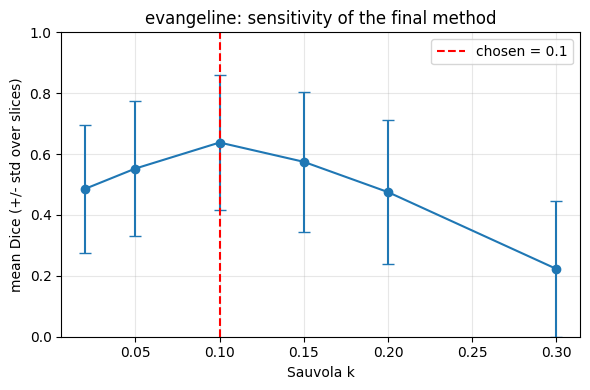

In [20]:
# save the sensitivity figure for the report
plt.figure(figsize=(6, 4))
plt.errorbar(sweep["SAUVOLA_K"], sweep["mean Dice"], yerr=sweep["std Dice"], marker="o", capsize=4)
plt.axvline(chosen, color="red", linestyle="--", label=f"chosen = {chosen}")
plt.xlabel("Sauvola k")
plt.ylabel("mean Dice (+/- std over slices)")
plt.ylim(0, 1)
plt.title(f"{NAME}: sensitivity of the final method")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIGS + "/" + NAME + "_p2_sensitivity.png", dpi=120)
plt.show()